# Mini-Project 6: Fetching and Displaying a Weather Forecast with Python Web APIs
**MSCS & MSDS OOP with Python — Assignment 2, Advent 2026**


## Configuration


In [2]:
CITY = "Kampala"
CANDIDATE_INDEX = 0
FORECAST_DAYS = 7
UNIVERSITY_EMAIL = "ronaldmumbere012@gamil.com"


## Imports and project setup

In [3]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.weather import (Location, WeatherError, WeatherAPIError, InvalidLocationError, NoLocationsError, InvalidForecastError, geocode, geocode_requests, geocode_urllib, choose_location, get_forecast, parse_locations, parse_forecast, describe_weather, summary, plot_forecast, get_norway_forecast, parse_norway, request_json, validate_coordinates)
def load_sample(filename):
    with open(ROOT / "samples" / filename, encoding="utf-8") as f: return json.load(f)
print("Project folder:", ROOT)


Project folder: D:\MSDS\OOP\Assignment 2 mini project\mini_project_6_weather


## HTTP fundamentals
The two functions below request the same Open-Meteo geocoding endpoint. The requests version uses `params=` and both use a timeout. The code prints HTTP status, Content-Type and elapsed seconds when connected.

In [5]:


from pathlib import Path
import sys

# Locate the project folder
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Import functions from the weather module
from src.weather import (
    geocode_urllib,
    geocode_requests,
    WeatherError
)

# Configuration
CITY = "Kampala"
TIMEOUT_SECONDS = 15

# Compare urllib and requests
for method in (geocode_urllib, geocode_requests):

    try:
        places, meta = method(
            CITY,
            timeout=TIMEOUT_SECONDS
        )

        print("\nMethod:", method.__name__)
        print("HTTP status:", meta["status_code"])
        print("Content type:", meta["content_type"])
        print("Response time:", meta["response_seconds"], "seconds")
        print("Locations found:", len(places))

        for index, place in enumerate(places):
            print(f"{index + 1}. {place.label}")

    except WeatherError as exc:
        print(f"\n{method.__name__} failed: {exc}")

    except Exception as exc:
        print(
            f"\nUnexpected error in {method.__name__}: "
            f"{type(exc).__name__}: {exc}"
        )




Method: geocode_urllib
HTTP status: 200
Content type: application/json; charset=utf-8
Response time: 1.188 seconds
Locations found: 10
1. Kampala, Central Region, Uganda
2. Kampala, Montagnes, Ivory Coast
3. Kampala, Ituri, Democratic Republic of Congo
4. Kampala, South Kivu, Democratic Republic of Congo
5. Kampala, Eastern Province, Zambia
6. Kampala, South Sulawesi, Indonesia
7. Kampala, South Sulawesi, Indonesia
8. Kampala, South Sulawesi, Indonesia
9. Kampala, South Sulawesi, Indonesia
10. Kampala, South Sulawesi, Indonesia

Method: geocode_requests
HTTP status: 200
Content type: application/json; charset=utf-8
Response time: 0.806 seconds
Locations found: 10
1. Kampala, Central Region, Uganda
2. Kampala, Montagnes, Ivory Coast
3. Kampala, Ituri, Democratic Republic of Congo
4. Kampala, South Kivu, Democratic Republic of Congo
5. Kampala, Eastern Province, Zambia
6. Kampala, South Sulawesi, Indonesia
7. Kampala, South Sulawesi, Indonesia
8. Kampala, South Sulawesi, Indonesia
9. Ka

## Geocoding and daily forecast
When a city name has multiple matches, inspect the candidate table and set `CANDIDATE_INDEX` in the configuration cell. The notebook does not pause for keyboard input.

In [6]:
LIVE_GEOCODING = True
try:
    candidates = geocode(CITY, timeout=TIMEOUT_SECONDS)
    if not candidates: raise NoLocationsError("No city matches")
except WeatherError as exc:
    LIVE_GEOCODING = False
    print("Live geocoding unavailable; using INVENTED SAMPLE JSON:", exc)
    candidates = parse_locations(load_sample("geocoding_sample.json"))
for i, place in enumerate(candidates): print(f"[{i}] {place.label} ({place.latitude}, {place.longitude}), {place.timezone}")
location = choose_location(candidates, CANDIDATE_INDEX)
print("Selected:", location.label)


[0] Kampala, Central Region, Uganda (0.31628, 32.58219), Africa/Kampala
[1] Kampala, Montagnes, Ivory Coast (7.32344, -7.68519), Africa/Abidjan
[2] Kampala, Ituri, Democratic Republic of Congo (2.30086, 30.59269), Africa/Lubumbashi
[3] Kampala, South Kivu, Democratic Republic of Congo (-2.19509, 27.74864), Africa/Lubumbashi
[4] Kampala, Eastern Province, Zambia (-14.41129, 31.6098), Africa/Lusaka
[5] Kampala, South Sulawesi, Indonesia (-5.0135, 119.5249), Asia/Makassar
[6] Kampala, South Sulawesi, Indonesia (-5.0031, 119.7811), Asia/Makassar
[7] Kampala, South Sulawesi, Indonesia (-5.1504, 120.0588), Asia/Makassar
[8] Kampala, South Sulawesi, Indonesia (-5.1541, 120.223), Asia/Makassar
[9] Kampala, South Sulawesi, Indonesia (-5.4758, 120.0053), Asia/Makassar
Selected: Kampala, Central Region, Uganda


In [7]:
LIVE_FORECAST = False
try:
    if not LIVE_GEOCODING: raise WeatherAPIError("Offline geocoding: do not mix sample coordinates with live forecast")
    payload, forecast_meta = get_forecast(location.latitude, location.longitude, FORECAST_DAYS, timezone_name=location.timezone, timeout=TIMEOUT_SECONDS)
    LIVE_FORECAST = True
except WeatherError as exc:
    print("Live forecast unavailable; using INVENTED SAMPLE JSON:", exc)
    payload = load_sample("open_meteo_sample.json")
forecast_table = parse_forecast(payload)
print("LIVE Open-Meteo forecast" if LIVE_FORECAST else "INVENTED SAMPLE — NOT CURRENT WEATHER")
display(forecast_table)
print(summary(forecast_table, location))


LIVE Open-Meteo forecast


,Date,Max temperature (°C),Min temperature (°C),Precipitation (mm),Max wind (km/h),Weather
0,2026-10-17,24.5,18.1,22.6,10.3,Moderate rain showers
1,2026-10-18,26.7,18.7,3.6,9.5,Moderate rain showers
2,2026-10-19,27.2,18.6,1.2,8.4,Light drizzle
3,2026-10-20,27.3,18.7,11.4,13.5,Moderate rain showers
4,2026-10-21,27.6,19.2,1.2,10.8,Light drizzle
5,2026-10-22,27.9,19.4,0.9,10.6,Light drizzle
6,2026-10-23,27.4,19.3,0.6,7.7,Light drizzle


Kampala, Central Region, Uganda: 7-day forecast. Maximum temperatures 24.5–27.9 °C; total precipitation 41.5 mm. Source: Open-Meteo (open-meteo.com).


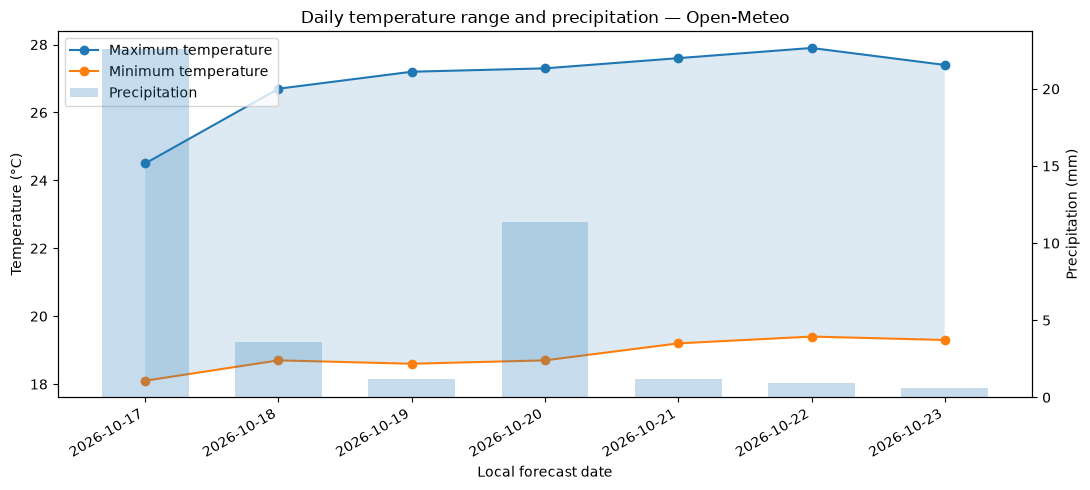

In [8]:
figure = plot_forecast(forecast_table)
plt.show()


## MET Norway second source


In [ ]:
LIVE_NORWAY = False
if UNIVERSITY_EMAIL.strip() and "@" in UNIVERSITY_EMAIL and not UNIVERSITY_EMAIL.endswith("@example.com") and LIVE_GEOCODING:
    try:
        norway_data, norway_meta = get_norway_forecast(location.latitude,location.longitude,contact_email=UNIVERSITY_EMAIL,timeout=TIMEOUT_SECONDS)
        LIVE_NORWAY = True
    except WeatherError as exc:
        print("MET Norway request unavailable:",exc)
if not LIVE_NORWAY:
    norway_data = load_sample("met_norway_sample.json")
    print("INVENTED MET Norway SAMPLE — not live weather. Set UNIVERSITY_EMAIL to enable live request.")
norway_table = parse_norway(norway_data)
display(norway_table.head(8))
print("Source:", "MET Norway (api.met.no)" if LIVE_NORWAY else "Invented sample JSON illustrating MET Norway schema")


## Failure demonstrations

In [10]:
import requests
class OfflineSession:
    def get(self,*args,**kwargs): raise requests.ConnectionError("Simulated offline network")
for label, action in [
    ("Invalid city", lambda: geocode(" ")),
    ("Invalid latitude", lambda: validate_coordinates(1000,32)),
    ("No matches", lambda: choose_location(parse_locations({"results":[]}))),
    ("Simulated no network", lambda: request_json("https://example.invalid",session=OfflineSession(),retries=1,backoff=0)),
]:
    try: action()
    except (WeatherError,ValueError) as exc: print(label,"->",type(exc).__name__,str(exc)[:120])
if LIVE_GEOCODING:
    try: geocode_requests(CITY,timeout=0.000001)
    except WeatherError as exc: print("Tiny timeout ->",type(exc).__name__,str(exc)[:120])
else: print("Tiny timeout live test skipped because network is unavailable")


Invalid city -> InvalidLocationError Enter at least two letters
Invalid latitude -> InvalidLocationError Latitude must be -90 to 90; longitude -180 to 180.
No matches -> NoLocationsError No matching locations
Simulated no network -> WeatherAPIError Failed after 2 attempt(s): Simulated offline network
Tiny timeout -> WeatherAPIError Failed after 3 attempt(s): HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with


## 7. Offline checks

In [11]:
geo = load_sample("geocoding_sample.json")
weather = load_sample("open_meteo_sample.json")
assert len(parse_locations(geo)) == 2
assert parse_locations({}) == []
assert choose_location(parse_locations(geo),1).country == "Sampleland"
assert describe_weather(61) == "Slight rain"
assert describe_weather(999).startswith("Unknown")
assert len(parse_forecast(weather)) == 3
assert parse_forecast(weather)["Precipitation (mm)"].sum() == 10.6
assert len(parse_norway(load_sample("met_norway_sample.json"))) == 1
try: parse_forecast({"daily":{"time":["2026-10-17"]}})
except InvalidForecastError: pass
else: raise AssertionError("Expected malformed forecast to fail")
print("All nine offline assertions passed.")


All nine offline assertions passed.


## Discussion and limitations 

### Data flow and program design

## Discussion and Limitations

The project demonstrates how Python can be used to retrieve and display weather forecasts using Open-Meteo and MET Norway APIs. Both `urllib` and `requests` are used to access weather data, although `requests` is easier to work with. The information is processed using Pandas and presented in tables and charts showing temperature, rainfall, wind speed and weather conditions.

The program also handles common errors such as invalid locations, network failures and unavailable APIs. However, it depends on internet access and the availability of the weather services. Forecasts from the two sources may differ because they use different models and are updated at different times.

The project also considers data privacy since location information is shared with external APIs. It follows the need for proper API identification and data attribution. However, it does not cover severe weather alerts, historical weather analysis or long-term climate predictions.

Overall, the project shows how Python can be used to collect, analyse and visualise weather information. It is mainly intended for learning purposes and would require further testing and improvements before being used as a reliable public weather information system.

### Comparing urllib and requests

Part A compares two ways of getting location information from the Open-Meteo API using Python. The first uses urllib, which comes with Python and does not require installing another library. It allows us to control how requests are sent, but it takes more code to handle responses and errors. The second uses requests, which is simpler because it handles things like query parameters, timeouts and JSON responses more easily.

The notebook also checks the HTTP status code, content type and response time to see whether the request was successful. However, a successful response does not always mean the data is correct, so the program also checks the JSON structure. Response times may vary depending on internet speed and server availability. Both methods work well, but requests is used for the main weather calculations because it is easier to use and handle errors.

### Reliability, retries and failure cases

Weather APIs depend on internet access and external servers, so requests may sometimes fail because of poor connectivity, server problems or slow responses. To handle this, the program sets a time limit for each request and checks whether the response is successful. If a temporary problem occurs, it tries again after a short delay, which increases with each attempt. However, the number of retries is limited to prevent the program from waiting too long. If the request still fails, the program displays a clear error message.

The program also checks the information entered before sending a request. For example, latitude must be between -90 and 90 degrees, while longitude must be between -180 and 180 degrees. It also checks the number of forecast days and whether the weather data received is complete. Tests are included to see how the program handles invalid locations, missing data, incorrect coordinates and network failures. Some failures are simulated to make sure the error-handling functions work as expected.

When the internet connection is unavailable, the notebook uses saved sample weather data to demonstrate how the tables and charts work. However, this information is only for testing and does not represent the current weather. Live forecasts should therefore be clearly identified, including their source and the time the data was retrieved.

### Second provider and interpreting differences

MET Norway Locationforecast 2.0 is used as a second source of weather information for the same location. Unlike Open-Meteo, which provides daily forecasts, MET Norway gives weather information at different times of the day. The project uses this data to show temperature, wind speed and expected rainfall for the next hour where available. However, the results from the two APIs cannot be compared directly because they use different time periods, timezones and forecasting models. For a proper comparison, the data would first need to be organised into matching time periods and units.

MET Norway also requires users to identify themselves when accessing its API. For this reason, the notebook allows the student to enter their own university email address before making a request. The email is not included directly in the shared code. The program also identifies the source of the weather data and limits requests to the selected location to avoid unnecessary use of the API.

### Licensing, usage and a real product

Open-Meteo and MET Norway provide weather data that can be accessed online, but this does not mean their services can be used without restrictions. Open-Meteo has guidelines on how its data should be used, including limits on requests, proper acknowledgement of the source and different conditions for commercial use. Since this project is for learning purposes, it uses the API to demonstrate how weather information can be collected and displayed. Anyone planning to use the same API for business would need to check the terms and obtain the necessary permission or subscription.

MET Norway also allows access to its weather data but requires users to acknowledge the source, identify themselves through a valid User-Agent and avoid making unnecessary requests. A real weather application would need to follow these requirements and manage API requests carefully to avoid overloading the service. Since API conditions may change, the project includes links to the providers' documentation for reference.

The project also includes sample weather data to allow testing when the internet is unavailable. This data was created for demonstration and does not represent actual weather observations from either provider. It should therefore not be used to make real weather-related decisions. When live weather data is used, the source and date of retrieval should be clearly indicated.

### Privacy, interpretation and limitations

When the program searches for a city, it sends the location name to an external weather service. The provider may also receive information such as the user's IP address and the time of the request. The weather API also receives the coordinates of the selected location. For this project, we use general city locations rather than personal home addresses to reduce privacy concerns. If the program were used by the public, users would need to know how their location information is collected, used and stored.

The weather charts help us understand expected temperatures, rainfall and wind conditions, but forecasts are not always accurate. For example, the daily rainfall total does not show exactly when it will rain, and wind speed may vary across locations. Forecasts can also change as new weather information becomes available. The project does not include severe weather warnings, long-term forecast accuracy checks or automatic storage of previously retrieved data.

Overall, the project shows how Python can be used to search for locations, collect weather data and present the results in tables and charts. It also shows that working with APIs involves more than retrieving data. We need to handle errors, check the information received, manage unavailable services and consider the privacy of users.

## References and AI use declaration
- Open-Meteo API documentation: https://open-meteo.com/en/docs
- Open-Meteo geocoding documentation: https://open-meteo.com/en/docs/geocoding-api
- Open-Meteo terms: https://open-meteo.com/en/terms
- MET Norway Locationforecast documentation: https://api.met.no/weatherapi/locationforecast/2.0/documentation
- MET Norway API conditions: https://api.met.no/doc/TermsOfService
- MET Norway licensing information: https://api.met.no/doc/License